# 1. Google News front page, 2022–2026

Rebuilds `data/google_news_front_page/` from the Internet Archive:
1. list the archived snapshots of `news.google.com/home`;
2. download the sampled snapshots;
3. read the stories out of each page;
4. tag each outlet with its payment group.

Raw pages go to `cache/` (not in the repository); tables go to `outputs/`. The full sample is 1,474 pages (about 2.4 GB, several hours at 6 s per request): set `LIMIT` to try a few first.

In [ ]:
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'collection' else Path.cwd()   # repository root
RAW, CACHE, OUT = ROOT / 'data' / 'raw', ROOT / 'cache', ROOT / 'outputs'
CACHE.mkdir(exist_ok=True); OUT.mkdir(exist_ok=True)
import csv, gzip, json, random, re, time, unicodedata
from urllib.parse import urlsplit
import numpy as np, pandas as pd, requests
from rapidfuzz import fuzz, process

EDITIONS = {'en-CA': 'https://news.google.com/home?hl=en-CA&gl=CA&ceid=CA:en',
            'fr-CA': 'https://news.google.com/home?hl=fr-CA&gl=CA&ceid=CA:fr'}
GAP = 6        # seconds between requests to the Archive
LIMIT = 10     # snapshots to download in this run; None = all
HEADERS = {'User-Agent': 'INSE6450 student research (archived Google News pages)'}

## Step 1. List the snapshots (optional)

The Archive's CDX index lists every saved copy. The sample used in the analysis is already in `data/google_news_front_page/snapshots.csv` (one random snapshot per edition per 2-day period, seed 6450), so this step only matters for drawing a new sample. The Archive keeps adding snapshots, so a new draw will differ.

In [ ]:
def list_snapshots(edition):
    r = requests.get('https://web.archive.org/cdx/search/cdx', headers=HEADERS, timeout=300,
                     params={'url': EDITIONS[edition], 'output': 'json', 'filter': 'statuscode:200',
                             'from': '2022', 'fl': 'timestamp,original,length'})
    rows = r.json()
    return pd.DataFrame(rows[1:], columns=rows[0]).assign(edition=edition)

def draw_sample(cdx, every_days=2, seed=6450):
    rng = np.random.default_rng(seed)
    cdx = cdx.assign(t=pd.to_datetime(cdx.timestamp, format='%Y%m%d%H%M%S'))
    out = []
    for ed, g in cdx.groupby('edition'):
        g = g.assign(bin=(g.t - g.t.min().normalize()).dt.days // every_days)
        out += [b.sample(1, random_state=rng.integers(1e9)) for _, b in g.groupby('bin')]
    return pd.concat(out)[['timestamp', 'edition']].assign(purpose='main')

# cdx = pd.concat([list_snapshots(ed) for ed in EDITIONS]); print(cdx.groupby('edition').size())
# sample = draw_sample(cdx)
sample = pd.read_csv(ROOT / 'data' / 'google_news_front_page' / 'snapshots.csv', dtype={'timestamp': str})
print(sample.purpose.value_counts())

## Step 2. Download

Each snapshot is fetched unmodified (`id_` in the address), one at a time. The Archive sometimes serves a nearby snapshot instead of the one asked for: the served time is recorded, and pages more than 3 hours off are excluded later. On HTTP 503 (Archive overloaded) the request is retried after a pause.

In [ ]:
def fetch(ts, edition):
    path = CACHE / 'front_page' / f'{ts}_{edition}.html.gz'
    if path.exists():
        return 'cached', None
    url = f'https://web.archive.org/web/{ts}id_/{EDITIONS[edition]}'
    for wait in (0, 60, 120, 240):
        time.sleep(wait)
        try:
            r = requests.get(url, headers=HEADERS, timeout=120)
        except requests.RequestException:
            continue
        if r.status_code == 200:
            path.parent.mkdir(exist_ok=True)
            with gzip.open(path, 'wt', encoding='utf-8') as f:
                f.write(r.text)
            served = re.search(r'/web/(\d{14})', r.url)
            return 200, served.group(1) if served else ts
        if r.status_code not in (429, 500, 502, 503, 504):
            return r.status_code, None
    return 'failed', None

log = []
todo = sample[sample.purpose.isin(['main', 'repeat'])]
for i, s in enumerate(todo.head(LIMIT).itertuples() if LIMIT else todo.itertuples()):
    status, served = fetch(s.timestamp, s.edition)
    log.append({'timestamp': s.timestamp, 'edition': s.edition, 'status': status, 'served_timestamp': served})
    if status != 'cached':
        time.sleep(GAP + random.uniform(0, 2))
log = pd.DataFrame(log)
log.to_csv(OUT / 'front_page_download_log.csv', index=False)
log.status.value_counts()

## Step 3. Read the stories out of each page

The page carries its stories as JSON inside `AF_initDataCallback(...)` with the key `gbres`:
- sections ("Top stories", "Local news", ...);
- each section's story cards;
- in each card, a lead article (slot 0) and related articles.

Each article record holds the headline, the publisher, the link and the publication time.

In [ ]:
def data_blocks(page):
    out = {}
    for m in re.finditer(r"AF_initDataCallback\(\{key: '([^']+)', hash: '[^']*', data:", page):
        end = page.find(', sideChannel: {}});', m.end())
        try:
            d = json.loads(page[m.end():end])
        except (json.JSONDecodeError, ValueError):
            continue
        if isinstance(d, list) and d and isinstance(d[0], str):
            out[d[0]] = d
    return out

def is_article(x):
    return (isinstance(x, list) and len(x) >= 20 and isinstance(x[1], list) and len(x[1]) == 2
            and isinstance(x[1][1], str) and isinstance(x[2], str) and len(x[2]) > 3)

def find_articles(x, depth=0):
    if depth > 12 or not isinstance(x, list):
        return []
    return [x] if is_article(x) else [a for v in x for a in find_articles(v, depth + 1)]

def first_str(x, pred, depth=0, skip_articles=True):
    if depth > 8:
        return None
    if isinstance(x, str):
        return x if pred(x) else None
    if isinstance(x, list) and not (skip_articles and depth and is_article(x)):
        for v in x:
            r = first_str(v, pred, depth + 1, skip_articles)
            if r:
                return r
    return None

def article(a):
    pub = next((v[2] for v in a[3:] if isinstance(v, list) and len(v) > 2 and isinstance(v[1], list)
                and len(v[1]) == 2 and isinstance(v[1][1], str) and v[1][1].startswith(('PublisherOf', 'CAAq'))
                and isinstance(v[2], str)), '')
    url = a[6] if len(a) > 6 and isinstance(a[6], str) and a[6].startswith('http') else (
        first_str(a, lambda s: s.startswith('http') and 'googleusercontent' not in s and 'news.google.com' not in s,
                  skip_articles=False) or '')
    t = a[4][0] if len(a) > 4 and isinstance(a[4], list) and a[4] and isinstance(a[4][0], int) else None
    return {'headline': a[2].strip(), 'publisher': pub, 'url': url, 'published_unix': t}

def domain(url):
    host = urlsplit(url).hostname or ''
    return re.sub(r'^(www\d?|m|amp|mobile)\.', '', host.lower())

def parse_page(page):
    """One row per article: section, card (0 = first story), slot (0 = lead), cluster size, story id."""
    d = data_blocks(page).get('gbres')
    rows = []
    for sec in (d[1] if d and isinstance(d[1], list) else []):
        title = sec[0][1] if isinstance(sec, list) and sec and isinstance(sec[0], list) and len(sec[0]) > 1 else None
        holders = [v for v in sec[1:] if isinstance(v, list) and find_articles(v)] if isinstance(title, str) else []
        cards = [c for c in holders[0] if find_articles(c)] if holders else []
        for k, card in enumerate(cards):
            arts = find_articles(card)
            sid = first_str(card, lambda s: s.startswith('CAAq') and len(s) > 30) or ''
            rows += [{'section': title, 'card': k, 'slot': j, 'cluster_size': len(arts), 'story_id': sid,
                      **article(a)} for j, a in enumerate(arts)]
    return rows

rows = []
for p in sorted((CACHE / 'front_page').glob('*.html.gz')):
    ts, edition = p.name.split('.')[0].split('_')
    page = gzip.open(p, 'rt', encoding='utf-8', errors='replace').read()
    rows += [{'timestamp': ts, 'edition': edition, **r} for r in parse_page(page)]
articles = pd.DataFrame(rows)
articles['outlet'] = articles.url.map(domain)
print(f"{articles.timestamp.nunique()} pages, {len(articles)} article slots")
articles.head()

## Step 4. Tag each outlet with its payment group

Inputs in `data/raw/`:
- `cjc_year1.csv`, `cjc_year2.csv`: Canadian Journalism Collective "payments to date";
- `open_call.txt`: Google's 2024 open-call list (legal name and website);
- `manual_tags.csv`: hand-checked outlets, which override the automatic match.

**Matching order:**
1. the hand tag;
2. the outlet's website in the open-call list, then its legal name in the CJC lists;
3. the publisher name matched to a CJC name (fuzzy).

**Groups:**
- `major` = paid, and the parent company got $2M+ in Year 2. Payees of one parent are added up: Québecor, Corus, Glacier.
- `local_en`, `franco`, `diaspora` = smaller paid outlets (diaspora = CJC sub-category A-7 or a third language).
- `cdn_unpaid`, `foreign`, `unknown` = everyone else.

In [ ]:
MAJOR_MIN = 2_000_000
PARENTS = {'quebecor': ('mediaqmi', 'groupe tva', 'numeriq'), 'corus': ('corus', '591987 b c'),
           'glacier': ('glacier media digital', 'castanet holdings', 'pacific coast publications', 'prairie newspaper group',
                       'western producer publications', 'alta newspaper group', 'tc publication')}
RENAMED = {'rogers': 'rogers communications'}           # same business, different Year 1 legal name
EXCLUDED = {'reuters canada'}                           # paid for its Canadian bureau; reuters.com is tagged foreign
PLATFORMS = {'youtube.com', 'msn.com', 'news.yahoo.com', 'apple.news', 'facebook.com', 'x.com', 'twitter.com',
             'instagram.com', 'tiktok.com'}             # outlet = platform:channel name
NOISE = r'\b(inc|ltd|limited|ltee|ltée|corp|corporation|company|co|lp|llp|partnership|societe|society|the|les|le|la|l|de|du|des|et|and|media|médias|medias|group|groupe|news)\b'
TLD = r'(?:ca|com|net|org|tv|fm|info|news|media|quebec|co|online|am|radio|live|press|today|blog|io|us|biz|me|cc)'
DOMAIN_RX = re.compile(r'(?i)(?<![\w@])(?:https?://)?(?:www\.)?([a-z0-9\-]+(?:\.[a-z0-9\-]+)*\.' + TLD + r')(?![\w\-])')

def norm(s):
    s = unicodedata.normalize('NFKD', str(s)).encode('ascii', 'ignore').decode().lower()
    return re.sub(r'\s+', ' ', re.sub(r'[^a-z0-9 ]+', ' ', s)).strip()

def norm_legal(s):
    return re.sub(r'\s+', ' ', re.sub(NOISE, ' ', norm(s))).strip()

def load_payees():
    rows = []
    for year in (1, 2):
        with open(RAW / f'cjc_year{year}.csv', newline='', encoding='utf-8-sig') as f:
            for r in csv.reader(f):
                if len(r) >= 5 and r[1].strip():
                    kind = ('broadcaster' if r[2].strip().lower() in ('broadcaster', 'radiodiffuseur') else
                            'cbc' if 'Canadian Broadcasting' in r[1] else 'publisher')
                    amount = re.sub(r'[^\d.,]', '', r[4]).replace(',', '')
                    rows.append({'year': year, 'operating': r[0].strip(), 'legal': r[1].strip(), 'type': kind,
                                 'sub': r[3].strip(), 'amount': float(amount) if amount else 0.0})
    df = pd.DataFrame(rows)
    df['key'] = df.legal.map(norm_legal)
    y2 = sorted(set(df[df.year == 2].key))
    remap = {}
    for k in set(df[df.year == 1].key) - set(y2):          # link Year 1 spellings to Year 2 names
        m = process.extractOne(k, y2, scorer=fuzz.token_sort_ratio)
        m2 = process.extractOne(k, y2, scorer=fuzz.token_set_ratio)
        if m and m[1] >= 92:
            remap[k] = m[0]
        elif m2 and m2[1] == 100 and len(k) >= 8 and (m2[0].startswith(k) or k.startswith(m2[0])):
            remap[k] = m2[0]
    remap.update({k: v for k, v in RENAMED.items() if k in set(df.key)})
    df['key'] = df.key.replace(remap)
    pay = df.groupby('key').agg(legal=('legal', 'last'), legal_all=('legal', lambda s: ' | '.join(dict.fromkeys(s))),
                                operating=('operating', lambda s: ' | '.join(dict.fromkeys(s))),
                                type=('type', 'first'), sub=('sub', lambda s: next((x for x in s if x), ''))).reset_index()
    for year in (1, 2):
        pay[f'y{year}'] = pay.key.map(df[df.year == year].groupby('key').amount.sum()).fillna(0)
    pay['op2'] = pay.key.map(df[df.year == 2].groupby('key').operating.last().str.lower()).fillna('')
    pay['parent'] = pay.op2.where(pay.op2.ne('') & pay.op2.duplicated(keep=False), pay.key)
    for parent, prefixes in PARENTS.items():
        pay.loc[pay.legal_all.map(norm).str.startswith(prefixes), 'parent'] = parent
    pay['y2_group'] = pay.groupby('parent').y2.transform('sum')
    pay['excluded'] = pay.key.isin(EXCLUDED)
    return pay

def load_open_call():
    rows, buf = [], []
    for line in (RAW / 'open_call.txt').read_text(encoding='utf-8').splitlines():
        line = line.strip()
        if not line or line.startswith('Legal Name Publication Name'):
            continue
        doms = [m for m in DOMAIN_RX.finditer(line) if not m.group(1).lower().startswith(('apps.apple', 'play.google', 'youtube'))]
        if not doms:
            buf.append(line)
            continue
        text = ' '.join(buf + [line[:doms[0].start()]]).strip()
        lang = line[doms[-1].end():].strip()
        rows += [{'text': text, 'domain': re.sub(r'^www\.', '', m.group(1).lower()), 'language': lang} for m in doms]
        if lang or text:
            buf = []
    return pd.DataFrame(rows).drop_duplicates()

def tag(outlets, pay, oc):
    """outlets: one row per outlet with columns domain, publisher, n_slots, n_fr."""
    names = {norm(n): k for k, ops, lg in zip(pay.key, pay.operating, pay.legal) for n in ops.split(' | ') + [lg]}
    legal_norm = {k: norm(lg) for k, lg in zip(pay.key, pay.legal)}
    variants = [(k, norm(v)) for k, la in zip(pay.key, pay.legal_all) for v in la.split(' | ')]
    man = pd.read_csv(RAW / 'manual_tags.csv', dtype=str, keep_default_na=False).set_index('domain')
    def manual_key(d):                                   # hand tag for the domain or a parent domain
        parts = d.split('.')
        return next((x for x in ['.'.join(parts[i:]) for i in range(len(parts) - 1)] if x in man.index), None)
    recs = []
    for o in outlets.itertuples():
        d, pub, mk = o.domain, o.publisher, manual_key(o.domain)
        key, basis, oc_lang = None, '', ''
        hits = oc[(oc.domain == d) | oc.domain.map(lambda x: d.endswith('.' + x))]
        if len(hits):
            oc_lang = hits.language.iloc[0]
        if mk:
            pl = man.loc[mk, 'payee_legal']
            basis = 'manual' if pl and pl.lower() != 'none' else 'manual: not paid'
            if basis == 'manual':
                n = norm(pl)
                exact = [k for k, v in variants if v == n or (len(n) >= 15 and v.startswith(n))]
                key = exact[0] if exact else next(k for k, v in legal_norm.items()
                                                  if v == process.extractOne(n, list(legal_norm.values()), scorer=fuzz.ratio)[0])
        if not basis and len(hits):                      # open-call row starts with the payee's legal name
            for t in hits.text:
                nt = norm(t)
                cands = [(len(lg), k) for k, lg in legal_norm.items() if len(lg) >= 6 and fuzz.ratio(lg, nt[:len(lg)]) >= 92]
                if cands:
                    key, basis = max(cands)[1], 'open call'
                    break
        tld = d.split(':')[0].rsplit('.', 1)[-1]
        foreign_cc = len(tld) == 2 and tld not in ('ca', 'tv', 'fm', 'io', 'co', 'me', 'am', 'cc')
        if not basis and pub and ':' not in d and not foreign_cc:
            m = process.extractOne(norm(pub), list(names), scorer=fuzz.ratio)
            if m and m[1] >= 97 and len(m[0]) >= 5:
                key, basis = names[m[0]], 'publisher name'
        p = pay[pay.key == key].iloc[0] if key else None
        mrow = man.loc[mk] if mk else None
        country = (mrow['country'] if mrow is not None and mrow['country'] else
                   'CA' if key or len(hits) or d.endswith('.ca') else tld.upper() if foreign_cc else '')
        lang = (mrow['language'] if mrow is not None and mrow['language'] else
                'fr' if (oc_lang and re.search(r'(?i)fran[cç]ais|french', oc_lang) and not re.search(r'(?i)english|anglais', oc_lang))
                or (not oc_lang and o.n_fr > o.n_slots / 2) else 'en')
        if p is not None:
            big = p.y2_group >= MAJOR_MIN or (p.y2 == 0 and p.y1 >= MAJOR_MIN)
            small = 'diaspora' if p['sub'] == 'A-7' or lang not in ('en', 'fr', 'bi') else 'franco' if lang == 'fr' else 'local_en'
            group = 'major' if big else small
        else:
            group = 'cdn_unpaid' if country == 'CA' else 'foreign' if country else 'unknown'
        if mrow is not None and mrow.get('group', ''):
            group = mrow['group']
        recs.append({'domain': d, 'publisher': pub, 'n_slots': o.n_slots, 'group': group, 'match_basis': basis,
                     'payee_legal': p.legal if p is not None else '', 'cjc_y2': p.y2 if p is not None else 0,
                     'cjc_sub': p['sub'] if p is not None else '', 'language': lang, 'country': country})
    return pd.DataFrame(recs).sort_values('n_slots', ascending=False)

pay, oc = load_payees(), load_open_call()
articles['outlet'] = np.where(articles.outlet.isin(PLATFORMS), articles.outlet + ':' + articles.publisher, articles.outlet)
outlets = (articles.groupby('outlet').agg(publisher=('publisher', lambda x: x.value_counts().index[0]),
                                          n_slots=('outlet', 'size'), n_fr=('edition', lambda x: (x == 'fr-CA').sum()))
           .reset_index().rename(columns={'outlet': 'domain'}))
tags = tag(outlets, pay, oc)
articles = articles.merge(tags[['domain', 'group', 'cjc_y2', 'cjc_sub', 'payee_legal']].rename(columns={'domain': 'outlet'}),
                          on='outlet', how='left')
articles.to_csv(OUT / 'front_page_articles.csv', index=False)
tags.to_csv(OUT / 'outlets.csv', index=False)
pay.to_csv(OUT / 'cjc_payees.csv', index=False)
tags.group.value_counts()

## Check against the dataset in `data/`

In [ ]:
ref = pd.read_csv(ROOT / 'data' / 'google_news_front_page' / 'front_page_articles.csv', dtype={'timestamp': str})
key = ['timestamp', 'section', 'card', 'slot']
both = articles.astype({'timestamp': str}).merge(ref[ref.timestamp.isin(articles.timestamp)], on=key, suffixes=('', '_ref'))
print(f"{len(both)} of {len(articles)} rebuilt slots found in data/; same headline: {(both.headline == both.headline_ref).mean():.1%}, "
      f"same outlet: {(both.outlet == both.outlet_ref).mean():.1%}, same group: {(both.group == both.group_ref).mean():.1%}")

## Step 5. Data report: missing values, summary stats, duplicates, example rows, plots

Reads the finished tables in `data/` (it does not use the pages downloaded above).
Saves `outputs/front_page_missingness.csv` (every column with missing values) and three plots, `outputs/front_page_*.png`, and prints the numbers used in Section 2 of the report.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# Setting root
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'data' / 'google_news_front_page').is_dir())
FP = ROOT / 'data' / 'google_news_front_page'
OUT = ROOT / 'outputs'
OUT.mkdir(exist_ok=True)

tables = {'snapshots': pd.read_csv(FP / 'snapshots.csv'),
          'front_page_articles': pd.read_csv(FP / 'front_page_articles.csv'),
          'outlets': pd.read_csv(FP / 'outlets.csv'),
          'cjc_payees': pd.read_csv(FP / 'cjc_payees.csv')}
snaps, arts_all = tables['snapshots'], tables['front_page_articles']

# analysis sample: one snapshot per edition per 2-day period, minus the 5 the Archive served from another date
keep = snaps[(snaps.purpose == 'main') & (snaps.exclude == False)]
arts = arts_all[arts_all.timestamp.isin(keep.timestamp)]
top = arts[arts.section.isin(['Top stories', 'À la une'])]   # the module we analyse
print('Snapshots drawn:', len(snaps), '| downloaded:', int(snaps.downloaded.sum()),
      '| same-day repeats:', int((snaps.purpose == 'repeat').sum()), '| excluded:', int((snaps.exclude == True).sum()),
      '| analysis sample:', len(keep), keep.edition.value_counts().to_dict())
print('Article rows:', len(arts), '| Top-stories slots:', len(top))

Snapshots drawn: 1480 | downloaded: 1474 | same-day repeats: 133 | excluded: 5 | analysis sample: 1336 {'en-CA': 723, 'fr-CA': 613}
Article rows: 16378 | Top-stories slots: 12382


In [2]:
# missing values (section 2.3): every column with any, saved for the report
tables['front_page_articles'] = arts
miss = pd.concat([pd.DataFrame({'table': n, 'column': d.columns, 'n_missing': d.isna().sum().values,
                                'pct_missing': (d.isna().mean() * 100).round(1).values}) for n, d in tables.items()])
miss = miss[miss.n_missing > 0]
miss.to_csv(OUT / 'front_page_missingness.csv', index=False)

# most gaps are structural, not lost data
print('story_id missing only on single-article cards:', set(arts[arts.story_id.isna()].cluster_size) == {1})
print('Payee missing only for unpaid/foreign/unknown outlets:',
      set(arts[arts.payee_legal.isna()].group) <= {'foreign', 'cdn_unpaid', 'unknown'})
miss

story_id missing only on single-article cards: True
Payee missing only for unpaid/foreign/unknown outlets: True


,table,column,n_missing,pct_missing
3,snapshots,served_timestamp,6,0.4
4,snapshots,served_offset_hours,6,0.4
5,snapshots,exclude,6,0.4
6,front_page_articles,story_id,7732,47.2
8,front_page_articles,publisher,17,0.1
9,front_page_articles,publication_id,107,0.7
17,front_page_articles,cjc_sub,3425,20.9
18,front_page_articles,payee_legal,3421,20.9
5,outlets,match_basis,230,35.2
6,outlets,payee_legal,421,64.4


In [3]:
# summary stats (section 2.3)
cards = top.groupby(['timestamp', 'card']).size()
age_h = (pd.to_datetime(arts.timestamp.astype(str), format='%Y%m%d%H%M%S')
         - pd.to_datetime(arts.published_unix, unit='s')).dt.total_seconds() / 3600
stats = pd.DataFrame({'articles per snapshot': arts.groupby('timestamp').size().describe(),
                      'articles per story card': cards.describe(),
                      'article age when shown (h)': age_h.describe()}).round(1)

# outliers and duplicates (section 2.4)
print('Snapshots served from another date (max offset, h):', snaps.served_offset_hours.abs().max())
print('Published after the snapshot:', int((age_h < 0).sum()), '| older than 7 days:', int((age_h > 168).sum()))
print('Exact duplicate rows:', arts.duplicated().sum(), '| same URL twice in one snapshot:',
      arts.duplicated(['timestamp', 'url']).sum(), '| unique URLs:', arts.url.nunique(), 'of', len(arts))

# class balance of the label: the lead (slot 0) of a card with 2+ articles
leads = top[(top.slot == 0) & (top.cluster_size >= 2)]
print('Leads:', len(leads), leads.group.value_counts().to_dict())
stats

Snapshots served from another date (max offset, h): 124.18
Published after the snapshot: 7 | older than 7 days: 33
Exact duplicate rows: 0 | same URL twice in one snapshot: 0 | unique URLs: 16221 of 16378
Leads: 2178 {'major': 1651, 'foreign': 450, 'franco': 44, 'cdn_unpaid': 19, 'local_en': 8, 'unknown': 6}


,articles per snapshot,articles per story card,article age when shown (h)
count,1336.0,5914.0,16378.0
mean,12.3,2.1,15.7
std,1.7,1.4,518.2
min,6.0,1.0,-1.4
25%,11.0,1.0,2.9
50%,13.0,1.0,6.9
75%,13.0,4.0,14.5
max,14.0,4.0,65915.3


In [4]:
# example rows (section 2.3): one story card with three articles
cols = ['timestamp', 'edition', 'section', 'card', 'slot', 'cluster_size', 'outlet', 'group', 'cjc_y2']
top[cols].head(3)

,timestamp,edition,section,card,slot,cluster_size,outlet,group,cjc_y2
0,20220516062725,fr-CA,À la une,0,0,3,journaldemontreal.com,major,2398347.94
1,20220516062725,fr-CA,À la une,0,1,3,lapresse.ca,major,3422033.04
2,20220516062725,fr-CA,À la une,0,2,3,ici.radio-canada.ca,major,7025932.56


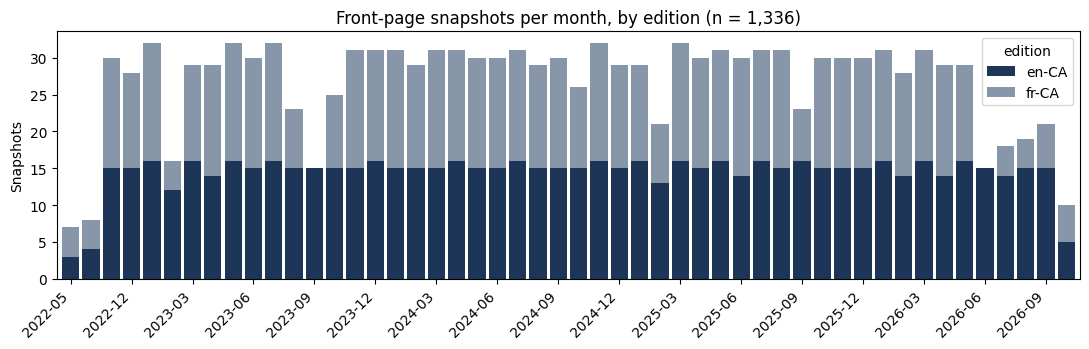

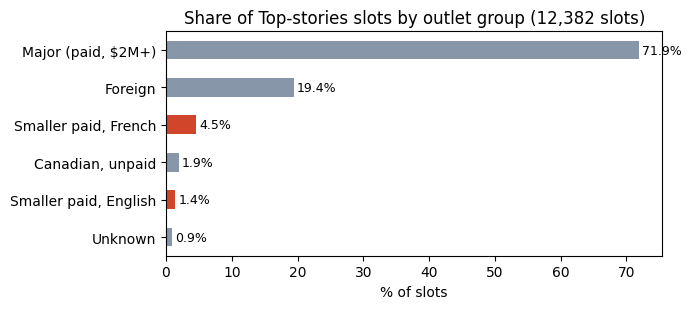

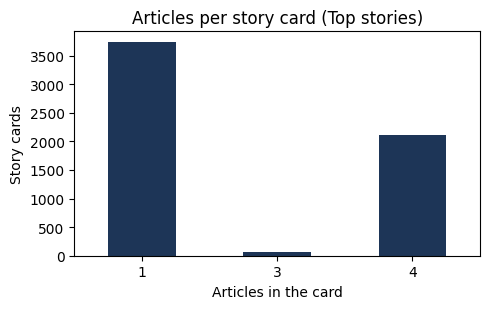

In [5]:
# plots (section 2.3)
NAMES = {'major': 'Major (paid, $2M+)', 'franco': 'Smaller paid, French', 'local_en': 'Smaller paid, English',
         'cdn_unpaid': 'Canadian, unpaid', 'foreign': 'Foreign', 'unknown': 'Unknown'}

# 1. coverage: snapshots per month, by edition (shows the Archive's gaps)
month = pd.to_datetime(keep.timestamp.astype(str), format='%Y%m%d%H%M%S').dt.to_period('M')
monthly = keep.assign(month=month).groupby(['month', 'edition']).size().unstack(fill_value=0)
ax = monthly.plot(kind='bar', stacked=True, figsize=(11, 3.6), width=0.85, color=['#1d3557', '#8796a8'])
ax.set(title=f'Front-page snapshots per month, by edition (n = {len(keep):,})', xlabel='', ylabel='Snapshots')
ax.set_xticks(range(0, len(monthly), 3), [str(m) for m in monthly.index[::3]], rotation=45, ha='right')
plt.tight_layout(); plt.savefig(OUT / 'front_page_snapshots_per_month.png', dpi=160); plt.show()

# 2. imbalance: share of Top-stories slots by outlet group
share = top.group.value_counts(normalize=True).mul(100).rename(NAMES).sort_values()
ax = share.plot(kind='barh', figsize=(7, 3.2), color=['#d1452a' if 'Smaller' in i else '#8796a8' for i in share.index])
ax.set(title=f'Share of Top-stories slots by outlet group ({len(top):,} slots)', xlabel='% of slots', ylabel='')
for i, v in enumerate(share):
    ax.text(v + 0.5, i, f'{v:.1f}%', va='center', fontsize=9)
plt.tight_layout(); plt.savefig(OUT / 'front_page_slots_by_group.png', dpi=160); plt.show()

# 3. histogram: articles per story card
ax = cards.value_counts().sort_index().plot(kind='bar', figsize=(5, 3.2), color='#1d3557', rot=0)
ax.set(title='Articles per story card (Top stories)', xlabel='Articles in the card', ylabel='Story cards')
plt.tight_layout(); plt.savefig(OUT / 'front_page_card_sizes.png', dpi=160); plt.show()